In [4]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, cross_val_predict
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance

from utils_pipeline import WeldImputer, feature_engineering
from utils_pipeline import metriques, evaluer_cv, resumer
from utils_pipeline import ridge, arbre, random_forest, xgboost

# --- Optuna : optimisation bayésienne des hyperparamètres -----------------------------------
import optuna
from optuna.samplers import TPESampler  # échantillonneur TPE, graine fixée pour la reproductibilité
from optuna.trial import TrialState     # filtrage des essais terminés dans les tableaux de résultats

c:\Users\andem\miniconda3\envs\soudure_acier\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
path_data_processed = r"..\1. Données\02_intermediate" + "/welddb_processed_vf.csv"
path_data_correspondance = r"..\1. Données\02_intermediate" + "/correspondance_between_names_units_vf.csv"

df = pd.read_csv(path_data_processed, sep = ";")
correspondance_between_names_units = pd.read_csv(path_data_correspondance, sep = ";")

In [6]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
N_FOLDS = 5
n_TRIALS = 100 #budget d'essaie pour Optuna qui est identique pour chaque modèle optimisé

mask_TARGETS = (correspondance_between_names_units["Role"] == "Quality indicator")
TARGETS = list(set(correspondance_between_names_units.loc[mask_TARGETS, "Feature"])& set(df.columns))
TARGETS_CAT = ["Charpy conforme"]
TARGETS_NUM = list(set(TARGETS) - set(TARGETS_CAT))
ID_COL = "Weld ID"

COL_NUM = [
    col for col in df.select_dtypes(include="number").columns
    if col not in TARGETS and col != ID_COL
]

COL_CAT = [
    col for col in df.select_dtypes(include="object").columns
    if col not in TARGETS and col != ID_COL
]

C:\Users\andem\AppData\Local\Temp\ipykernel_29580\3612539067.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  col for col in df.select_dtypes(include="object").columns


## 1. Introduction : prise de connaissance sur nos features et séparation des données en train/test

Avant de commencer la partie sur la prédiction de notre variable, cible nous devons d'abord définir le contexte. 

Le but de notre projet est de pouvoir prédire la qualité de soudure de l'acier. Cependant, nous n'avons pas de feature à proprement en parler sous un nom explicite "Qualité de variable", mais plus 5 indicateurs de qualités de la soudure. Plusieurs procédés sont disponibles, dans ce notebook nous allons essayer de faire une démarche plutôt classique, utilisant au plus les méthodes vu au sein du TD.

Pour ce faire, nous allons choisir de prédire les 5 indicateurs un par un, ceci dit qu'il y aura donc cinq modèles de prédictions différents (de régression ou de classification).

La démarche sera approximativement la suivante : 
1. Imputation des données
2. Réduction des variables
3. Recherche/Benchmark des modèles de prédictions tout en optimisant les paramètres

Etudions d'abord la distribution des features cibles pour guider un peu nos idées.

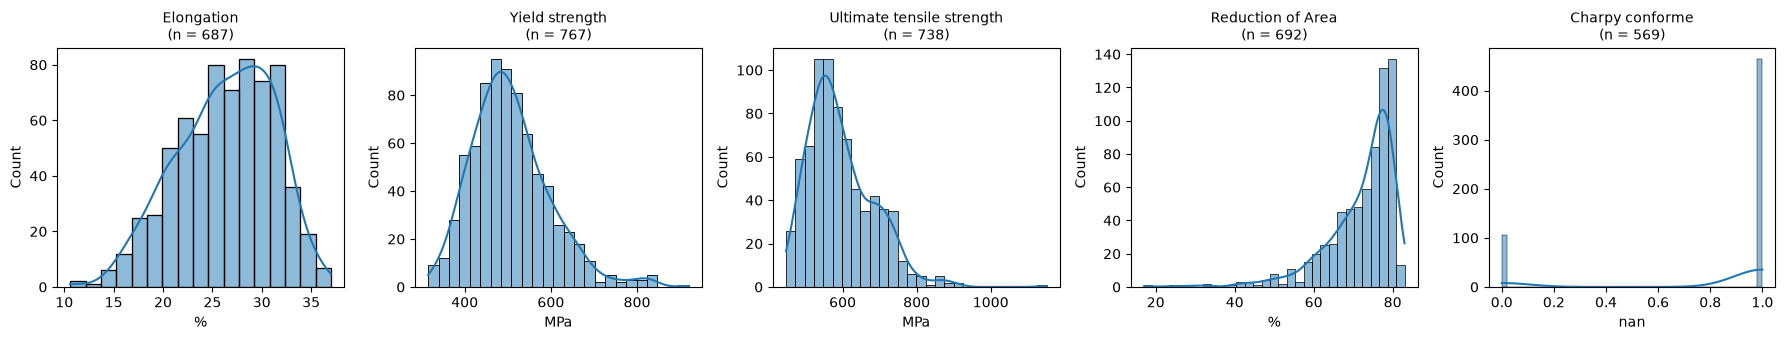

,count,mean,std,min,25%,50%,75%,max
Elongation,687.0,26.3,4.9,10.6,23.0,26.8,30.0,37.0
Yield strength,767.0,506.4,91.3,315.0,443.0,494.0,555.0,920.0
Ultimate tensile strength,738.0,594.4,88.6,447.0,532.8,575.5,647.0,1151.0
Reduction of Area,692.0,72.0,8.8,17.0,68.5,75.0,78.0,83.0
Charpy conforme,569.0,0.8,0.4,0.0,1.0,1.0,1.0,1.0


In [7]:
# distributions des targets 
fig, axes = plt.subplots(1, len(TARGETS), figsize=(18, 3.5))
for ax, t in zip(axes, TARGETS):
    sns.histplot(df[t].dropna(), ax=ax, kde=True)
    ax.set_title(f"{t}\n(n = {df[t].notna().sum()})", fontsize=10)
    ax.set_xlabel(correspondance_between_names_units.loc[correspondance_between_names_units['Feature'] == t, 'Unit'].values[0])
plt.tight_layout()
plt.show()

df[TARGETS].describe().T.round(1)

Elongation                   687
Yield strength               767
Ultimate tensile strength    738
Reduction of Area            692
Charpy conforme              569

Lignes avec au moins une cible : 1245
Lignes avec toutes les cibles  : 118
Lignes sans aucune cible       : 393


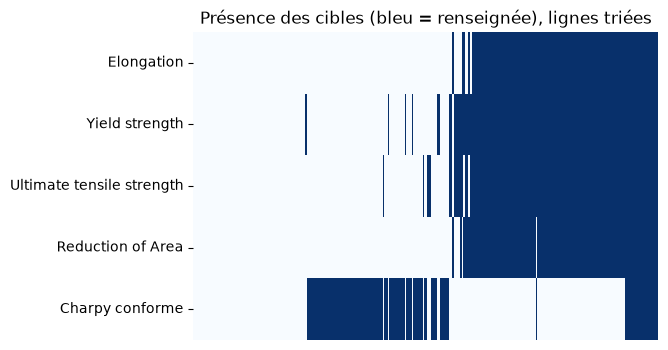

In [8]:
# observons la répartition des instances manquantes par cible
target_counts = df[TARGETS].notna().sum().rename("nb lignes étiquetées")
print(target_counts.to_string())
print(f"\nLignes avec au moins une cible : {df[TARGETS].notna().any(axis=1).sum()}")
print(f"Lignes avec toutes les cibles  : {df[TARGETS].notna().all(axis=1).sum()}")
print(f"Lignes sans aucune cible       : {df[TARGETS].isna().all(axis=1).sum()}")

plt.figure(figsize=(6, 4))
sns.heatmap(df[TARGETS].notna().T.astype(int).loc[:, df[TARGETS].notna().sum(axis=1).sort_values().index],
            cbar=False, cmap="Blues", xticklabels=False)
plt.title("Présence des cibles (bleu = renseignée), lignes triées")
plt.show()

Les éléments remarquables sont les suivants : 
- Seule la feature `Charpy conforme` est catégorielle, donc nous utiliserons une méthode de classification ;
- Le reste des features sont numériques, donc on utilisera une méthode de régression. 

La distribution de chacun des features cibles ne suivent pas tous une distribution gaussienne, même loin d'en être une. Ainsi pour éviter que lors du split train/test on a qu'une proportion de données identiques dans le groupe, on fera de la stratification. Le but serait de pouvoir obtenir une même distribution de variable cible dans les données d'entrainement et de test pour que le modèle apprend "mieux". 

**Dans le cas d'une validation croisée à k-folds, nous allons appliquer à chaque fold la stratifictaion.**

> Par ailleurs, on observe que quand la présence de la valeur de `Charpy conforme` est inversé à celle des autres cibles. Il faut avoir un point de vigilence sur la population d'instance de chaque cible, qu'elle ne sont pas forcément les mêmes. Dans le cadre de cette méthode classique, nous allons devoir exclure les instances où pour la cible étudiée sont vides. 
>
>Si on n'a pas d'instance dans la cible, on n'aura pas de "bonne réponse" pour évaluer notre prédiction. **Mais si on ne souhaite pas supprimer ces instances, il faudra donc passer à de l'apprentissage supervisé (une partie à traité plus tard).**

Chaque instance de notre jeu de données font partie d'un lot de soudure. Quand ils sont issus d'une même référence de soudure, ils sont donc très similaires. Pour éviter d'avoir de la fuite de données, nous allons donc chercher à mettre les instances de la même référence dans le même côté ie. soit dans train, soit dans test. C'est pourquoi ici, pour le split train/test, nous utiliserons la fonction `StratifiedGroupKFold`. Il répartit des groupes entiers dans K paquets, en choisissant la répartition qui rend la distribution de y la plus proche possible dans chaque paquet. Pour ce faire, nous allons juste prendre le premier fold pour notre split train/test. 

In [9]:
# Split des données en stratifiant et en fonction du Weld ID
target = "Yield strength" # essaie sur une cible à la fois
d = df[df[target].notna()].reset_index(drop=True)   # on ne garde que les lignes où la cible existe

# On retire les autres cibles des features (elles seraient une fuite)
X = d.drop(columns=TARGETS+[ID_COL])
y = d[target]
groups = d[ID_COL]

# Discrétisation de la cible en quantiles, uniquement pour stratifier
y_bins = pd.qcut(y, q=5, labels=False)

# 5 folds, soit environ 80/20 ; on prend le premier comme train/test
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(X, y_bins, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# Vérifications
print(len(train_idx), len(test_idx))
print(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))   # doit être vide
print(y_train.describe(), y_test.describe())

612 155
set()
count    612.000000
mean     505.715033
std       87.044215
min      315.000000
25%      443.000000
50%      494.000000
75%      556.250000
max      808.000000
Name: Yield strength, dtype: float64 count    155.000000
mean     508.922581
std      106.822436
min      329.000000
25%      445.000000
50%      492.000000
75%      552.500000
max      920.000000
Name: Yield strength, dtype: float64


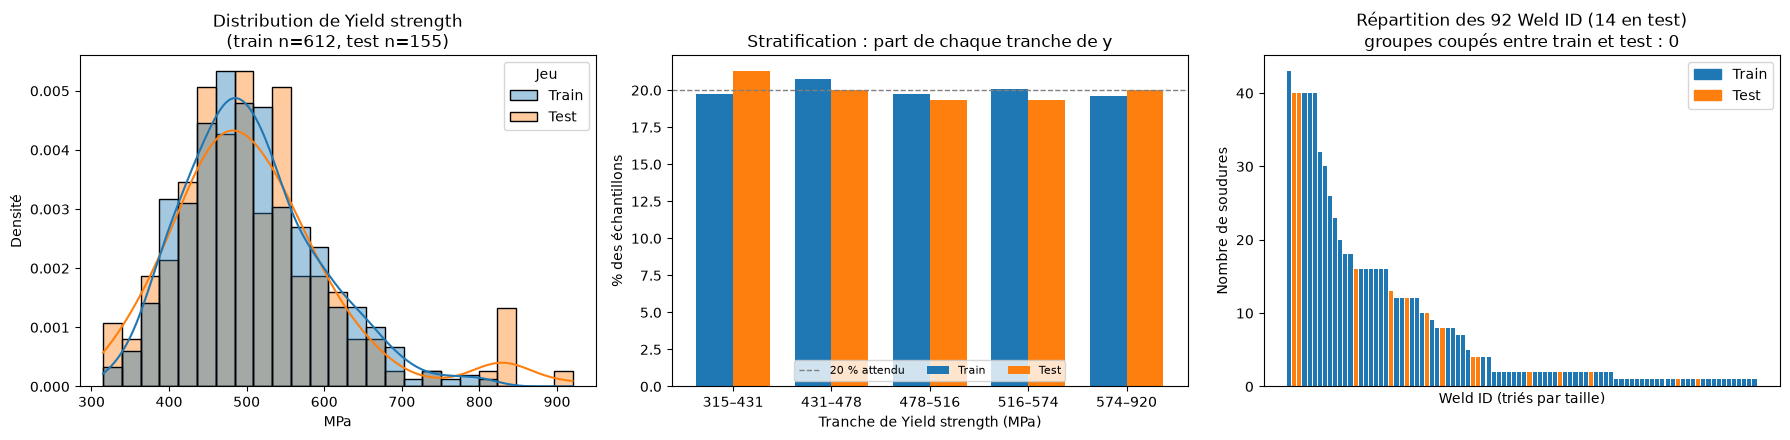

In [10]:
# Étiquette Train/Test pour chaque ligne de d
split = pd.Series("Train", index=d.index, name="Jeu")
split.iloc[test_idx] = "Test"
palette = {"Train": "#1f77b4", "Test": "#ff7f0e"}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1) Distribution de la cible (densité, pour comparer malgré les tailles différentes)
ax = axes[0]
sns.histplot(x=y, hue=split, stat="density", common_norm=False, kde=True,
             bins=25, palette=palette, alpha=0.4, ax=ax)
ax.set_title(f"Distribution de {target}\n(train n={len(y_train)}, test n={len(y_test)})")
ax.set_xlabel("MPa"); ax.set_ylabel("Densité")

# 2) Proportion de chaque tranche de quantile dans train et test
ax = axes[1]
props = (pd.crosstab(y_bins, split, normalize="columns") * 100)[["Train", "Test"]]
edges = pd.qcut(y, q=5, retbins=True)[1]
props.index = [f"{edges[i]:.0f}–{edges[i+1]:.0f}" for i in props.index]
props.plot.bar(ax=ax, color=[palette["Train"], palette["Test"]], rot=0, width=0.75)
ax.axhline(20, ls="--", c="grey", lw=1, label="20 % attendu")
ax.set_title("Stratification : part de chaque tranche de y")
ax.set_xlabel("Tranche de Yield strength (MPa)"); ax.set_ylabel("% des échantillons")
ax.legend(loc="lower center", ncol=3, fontsize=8)

# 3) Groupes : chaque barre = un Weld ID, colorée selon le côté où il est tombé
ax = axes[2]
g = (pd.DataFrame({"Weld ID": groups, "split": split})
       .groupby("Weld ID").agg(n=("split", "size"), split=("split", "first"))
       .sort_values("n", ascending=False))
n_split_groups = (pd.crosstab(groups, split) > 0).sum(axis=1).gt(1).sum()
ax.bar(range(len(g)), g["n"], color=g["split"].map(palette), width=0.8)
ax.set_title(f"Répartition des {len(g)} Weld ID ({(g['split']=='Test').sum()} en test)\n"
             f"groupes coupés entre train et test : {n_split_groups}")
ax.set_xlabel("Weld ID (triés par taille)"); ax.set_ylabel("Nombre de soudures")
ax.set_xticks([])
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()],
          labels=list(palette.keys()))

plt.tight_layout()
plt.show()

Dans les trois graphiques, on voit bien les points suivants :
- la répartition des instances dans le train et le test est très proche ; 
- pour chaque tranche de quantile, on a bien une répartition d'environ 20% dans le train et dans le test (car on a posé `q=5`) ;
- chaque barre indique une référence de soudure, la plus barre est dans le train. Cela peut potentiellement influencer notre prédiction, c'est pourquoi nous pouvons à la fin utiliser une validation croisée pour avoir une mesure d'erreur plus précise.

A partir de là, tous les données de test seront oubliés, on les sollicitera que lorsqu'on évaluera notre modèle.

## 2. Application de la méthode d'imputation et du feature engineering

On va donc pouvoir imputer nos données sélectionner en fonction de la cible. On utilisera la fonction préparer dans le `utils_pipeline.py`.

In [11]:
imp = WeldImputer()
X_train_imp = imp.fit_transform(X_train)   # fit sur le train uniquement
X_test_imp  = imp.transform(X_test)        # on applique les statistiques du train

print(X_train_imp.isna().sum()[lambda s: s > 0])   # NaN restants
print(X_test_imp.isna().sum()[lambda s: s > 0])

Series([], dtype: int64)
Series([], dtype: int64)


Maintenant, on applique la méthode de feature engineering définie dans le notebook 2.

In [12]:
X_train_fe = feature_engineering(X_train_imp)
X_test_fe  = feature_engineering(X_test_imp)

print(X_train_fe["CE_IIW"].describe())
print(X_train_fe["CE_IIW"].isna().sum(), X_test_fe["CE_IIW"].isna().sum())   # doit être 0 et 0

count    612.000000
mean       0.443930
std        0.373691
min        0.129667
25%        0.284667
50%        0.335333
75%        0.436317
max        2.327667
Name: CE_IIW, dtype: float64
0 0


In [13]:
# Variables après imputation (noms utilisés pour la sélection)
COL_CAT = ["Type of weld", "courant"]
COL_NUM = [c for c in X_train_fe.columns if c not in COL_CAT]

## 3. Fixation de la méthode de réduction de dimention

#### A. Sélection de variables : Forward

La réduction de dimension est un terme assez large, nous pouvons trouver pas mal de méthode comme la PCA, les méthodes stepwize ou le filtre par corrélation. Nous n'allons pas essayer la méthode de PCA, car son interprétation n'est pas si facile que de voir des variables en elle-même. 

Par ailleurs, la méthode de filtrage par corrélarion n'est pas si simple, car nous devons faire trois types de calcul : 
- Test de $\chi^2$ : entre les variables catégorielles ;
- Corrélation de spearman : entre les variables numériques ;
- Test de corrélation $\eta$. 
La question du choix de variables à supprimer pourrait aussi poser problème. 

Ainsi, nous pouvons tester la méthode de Forward pour trouver la liste des varaibles à supprimer. On choisira la meilleur taille $\mathcal{M}_k$ et le sous-ensemble de features $X_{forward}$ en utilisant la validation croisée. L'évaluation se fera par discrimination du RMSE donnée par le modèle de référence (ici le RandomForest).

In [53]:
# Pipeline pour l'encodage et la standardisation, et le modèle
def make_model(feats, model):
    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), [c for  c in feats if c in COL_NUM]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), [c for c in feats if c in COL_CAT]),
    ])
    return make_pipeline(preprocessor, clone(model))

In [54]:
# Sélection forward basée sur un algorithme de glouton
def forward_stepwise(X, y, model, cv, scoring="neg_root_mean_squared_error"):
    def train_r2(feats):
        """Étape : R² ajusté sur l'entraînement (sans validation croisée)."""
        pipe = make_model(feats, model)
        pipe.fit(X[feats], y)
        return r2_score(y, pipe.predict(X[feats]))

    def cv_score(feats):
        """Étape : score en validation croisée (M0 = modèle nul)."""
        if not feats:  # M_0 : prédit la moyenne, aucune variable
            pipe = DummyRegressor(strategy="mean")
            return cross_val_score(pipe, X, y, cv=cv, scoring=scoring).mean()
        pipe = make_model(feats, model)
        return cross_val_score(pipe, X[feats], y, cv=cv, scoring=scoring).mean()

    features = list(X.columns)
    selected = []
    models = [[]]                      # M_0 : modèle nul (aucune variable)
    train_scores = {(): 0.0}          # R² de M_0 = 0 par définition

    while len(selected) < len(features):
        candidates = [selected + [f] for f in features if f not in selected]  # (a)
        scores = [train_r2(c) for c in candidates]                            # (b)
        best = int(np.argmax(scores))
        selected = candidates[best]
        models.append(list(selected))
        train_scores[tuple(selected)] = scores[best]

    cv_scores = [cv_score(feats) for feats in models]
    best_k = int(np.argmax(cv_scores))
    best_feats = models[best_k]

    return models, cv_scores, best_feats

In [55]:
folds = list(sgkf.split(X_train_fe, y_bins.iloc[train_idx], groups.iloc[train_idx]))

models, cv_scores, best_feats = forward_stepwise(
    X_train_fe, y_train,
    model=RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    scoring="neg_root_mean_squared_error",
    cv=folds,
)

best_score = max(cv_scores)

best_k = cv_scores.index(best_score)

print(f"Meilleure RMSE : {-best_score:.2f} MPa avec {len(best_feats)} variables")

# garantie que la variable "Carbon concentration" est conservée
if "Carbon concentration" not in best_feats:
    best_feats.append("Carbon concentration")
    
print("Variables gardées :", best_feats)
print("Variables supprimées :", [f for f in X_train_fe.columns if f not in best_feats])


Meilleure RMSE : 52.21 MPa avec 14 variables
Variables gardées : ['CE_IIW', 'Post weld heat treatment temperature', 'Oxygen concentration', 'Vanadium concentration', 'Titanium concentration', 'Interpass temperature', 'Niobium concentration', 'Boron concentration', 'courant', 'Current', 'Carbon concentration', 'Molybdenum concentration', 'Heat input', 'Post weld heat treatment time']
Variables supprimées : ['Silicon concentration', 'Manganese concentration', 'Sulphur concentration', 'Phosphorus concentration', 'Nickel concentration', 'Chromium concentration', 'Copper concentration', 'Nitrogen concentration', 'Aluminium concentration', 'Voltage', 'Type of weld']


On retient ici que 14 variables on est été sélection, dont après `Carbon concentration` a été ajouté articiellement, car la littérature justifie que ce dernier apporte du durcissement en solution solide, augmente la trempabilité et la formation de carbures.

Cependant 52% (13/25) des features ont été retirés, ce qui est énorme. C'est pourquoi, il est aussi bien de pouvoir tester la solution sans suppresion de features. 

Ci-dessous, on voit bien que ce choix de sélection est fait en minimisant la RMSE avec notre modèle de référence.

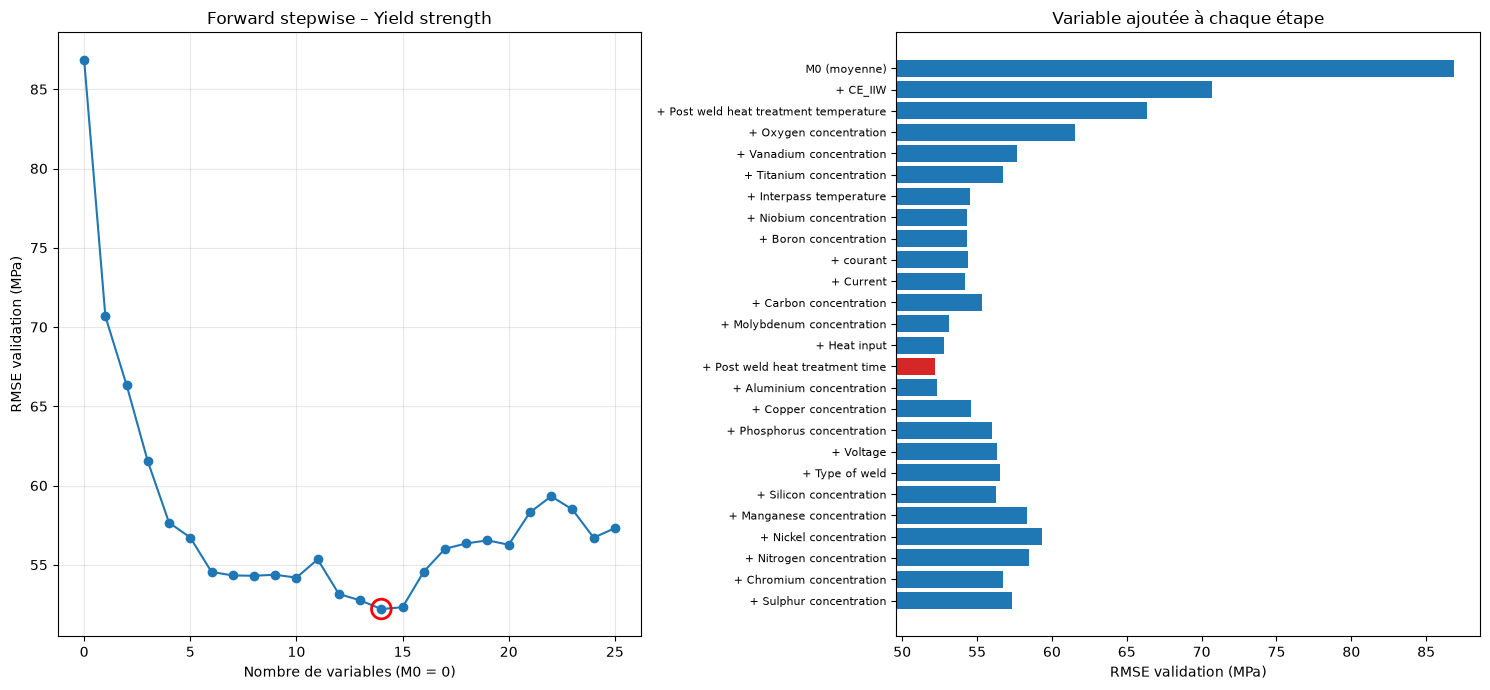

In [57]:
rmse = [-s for s in cv_scores]
labels = ["M0 (moyenne)" if not f else "+ " + f[-1] for f in models]
i_best = int(np.argmin(rmse))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))

# --- Courbe RMSE vs nombre de variables (M0 = 0 variable) ---
ax1.plot(range(len(rmse)), rmse, marker="o")
ax1.scatter(i_best, rmse[i_best], s=200, facecolors="none",
           edgecolors="red", linewidths=2, zorder=3)
ax1.set_xlabel("Nombre de variables (M0 = 0)")
ax1.set_ylabel("RMSE validation (MPa)")
ax1.set_title("Forward stepwise – Yield strength")
ax1.grid(alpha=0.3)

# --- Barres : variable ajoutée à chaque étape ---
colors = ["tab:red" if i == i_best else "tab:blue" for i in range(len(rmse))]
ax2.barh(range(len(rmse)), rmse, color=colors)
ax2.set_yticks(range(len(rmse)), labels, fontsize=8)
ax2.invert_yaxis()
ax2.set_xlim(min(rmse) * 0.95, max(rmse) * 1.02)
ax2.set_xlabel("RMSE validation (MPa)")
ax2.set_title("Variable ajoutée à chaque étape")

plt.tight_layout()
plt.show()

## 4. Sélection de modèle

Maintenant, nous allons attaquer à la partie sérieuse du projet "la sélection de modèle". Ici en principe nous avons plusieurs candidats de modèle, valable en régression ou en classification : 
- la régression linéaire / la classification binaire ;
- l'arbre de décision ;
- le Random Forest (basée sur la méthode de bagging) ;
- la régularisation de Ridge ;
- XGBoost (basée sur la méthode de boosting).

Pour cela, nous utiliserons Optuna pour faire le choix du modèle ou même des hyperparamètres.

#### Fonctions utiles

In [26]:
def construire_prep(COL_NUM, COL_CAT):
    return ColumnTransformer([
        ("num", "passthrough", COL_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), COL_CAT),
    ])

Pour faciliter le travail, nous avons écrit ici une fonction `optimiser` qui permet de faire la première partie de recherche.

Pour chaque modèle, les hyperparamètres sont recherchés avec **Optuna** (algorithme TPE, graine fixée), en minimisant le **RMSE moyen en validation croisée groupée** sur le jeu d'entraînement. Le prétraitement (imputation, encodage) est inclus dans le pipeline : il est donc réappris sur le train de chaque pli, sans fuite.

**Règle de l'erreur standard (« 1-SE »).** Retenir le meilleur essai est fragile : avec peu de soudures distinctes, l'écart entre deux essais est souvent inférieur au bruit de la validation croisée. La sélection se fait donc en trois temps :

1. On calcule l'erreur standard du meilleur essai : $SE = \dfrac{\sigma_{RMSE}}{\sqrt{K}}$, avec $K$ le nombre de plis.
2. On garde tous les essais « indiscernables » du meilleur, c'est-à-dire ceux dont le RMSE vérifie $RMSE \le RMSE_{\min} + SE$.
3. Parmi eux, on retient le **modèle le plus simple** selon un critère propre à chaque modèle (`SIMPLICITE`, par exemple profondeur plus faible ou régularisation plus forte).

**Justification.** À performance statistiquement équivalente, un modèle plus simple surapprend moins et généralise mieux à de nouvelles séries de soudures, ce qui est l'objectif ici.

**Sorties.** La fonction réévalue le modèle retenu en validation croisée (résultats stockés dans `registre[nom]`), affiche le nombre d'essais indiscernables, et renvoie le pipeline et ses hyperparamètres.

In [ ]:
def optimiser(nom, construire_modele, X_train, y_train,construire_prep, registre, n_trials=n_TRIALS):
    """Recherche les hyperparamètres d'un modèle avec Optuna, puis retient le modèle
    le plus simple parmi les essais statistiquement équivalents au meilleur (règle 1-SE)."""

    def objective(trial):
        # Pipeline complet : prétraitement + modèle dont les hyperparamètres sont proposés par Optuna
        # (le prétraitement est refait sur le train de chaque pli : pas de fuite)
        pipe = make_pipeline(construire_prep, construire_modele(trial))
        # Validation croisée groupée : renvoie les scores (dont le RMSE) de chaque pli
        res = evaluer_cv(pipe, X_train, y_train, folds)
        # Erreur standard du RMSE = écart-type entre plis / racine du nb de plis
        # (stockée dans l'essai pour la règle 1-SE plus bas)
        trial.set_user_attr("se", res["RMSE"].std() / np.sqrt(len(folds)))
        # Valeur à minimiser : RMSE moyen sur les plis
        return res["RMSE"].mean()

    # Étude Optuna : on minimise le RMSE, avec l'algorithme TPE (graine fixée = reproductible)
    study = optuna.create_study(direction="minimize", sampler=TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=n_TRIALS)
    # On ne garde que les essais terminés (on écarte les essais échoués ou élagués)
    essais = [t for t in study.trials if t.state == TrialState.COMPLETE]
    # Règle 1-SE : seuil = meilleur RMSE + son erreur standard
    seuil = study.best_value + study.best_trial.user_attrs["se"]
    # Essais "indiscernables" du meilleur : RMSE sous le seuil
    indisc = [t for t in essais if t.value <= seuil]
    # Parmi eux, on retient le plus simple selon le critère propre au modèle
    # (ex. profondeur plus faible, régularisation plus forte)
    retenu = min(indisc, key=lambda t: SIMPLICITE[nom](t.params))
    # Reconstruit le pipeline avec les hyperparamètres de l'essai retenu
    # (FixedTrial rejoue ces valeurs dans construire_modele)
    modele = make_pipeline(construire_prep,
                           construire_modele(optuna.trial.FixedTrial(retenu.params)))
    # Réévalue le modèle retenu en CV et stocke les résultats dans le registre global
    registre[nom] = evaluer_cv(modele, X_train, y_train, folds)
    # Résumé : combien d'essais sont équivalents au meilleur, lequel est retenu
    print(f"{nom} : {len(indisc)}/{len(essais)} essais indiscernables, "
          f"retenu n°{retenu.number} ({retenu.value:.1f} vs meilleur {study.best_value:.1f})")
    # Renvoie le pipeline (non entraîné) et ses hyperparamètres
    return modele, retenu.params

#### A. Méthode sans sélection de variables

In [31]:
# ==================================================================
# 0) Données : toutes les variables sont conservées
# ==================================================================
# Folds : les MÊMES pour tous les modèles, groupés sur Weld ID, calculés sur tout X_train
groups_train = groups.iloc[train_idx]
y_bins_train = y_bins.iloc[train_idx]
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(sgkf.split(X_train_fe, y_bins_train, groups_train))
COL_NUM_RED = COL_NUM
COL_CAT_RED = COL_CAT
X_train_red = X_train_fe
X_test_red = X_test_fe

In [32]:
registre = {}   # nom du modèle -> DataFrame des scores par fold

SIMPLICITE = {  # critère fixé à l'avance : plus petit = plus simple
    "Ridge":         lambda p: -p["alpha"],
    "Arbre":         lambda p: (p["max_depth"], -p["min_samples_leaf"]),
    "Random Forest": lambda p: (p["max_depth"], -p["min_samples_leaf"]),
    "XGBoost":       lambda p: (p["n_estimators"], p["max_depth"], -p["min_child_weight"]),
}

# Affichage des erreurs pour l'optimisation
optuna.logging.set_verbosity(optuna.logging.ERROR)

# Référence naïve : prédit toujours la moyenne (rien à régler)
registre["Baseline (moyenne)"] = evaluer_cv(make_pipeline(construire_prep(COL_NUM_RED,COL_CAT_RED), DummyRegressor()),
                                            X_train_red, y_train, folds)

modeles, params = {}, {}

# Modèles avec hyperparamètres réglés par Optuna
for nom, fn in [("Ridge", ridge), ("Arbre", arbre),
                ("Random Forest", random_forest), ("XGBoost", xgboost)]:
    modeles[nom], params[nom] = optimiser(nom, fn, X_train_red, y_train ,construire_prep(COL_NUM_RED, COL_CAT_RED),registre, n_trials=n_TRIALS, )


Ridge : 63/100 essais indiscernables, retenu n°78 (77.7 vs meilleur 77.2)
Arbre : 72/100 essais indiscernables, retenu n°5 (66.8 vs meilleur 64.6)
Random Forest : 98/100 essais indiscernables, retenu n°5 (58.5 vs meilleur 55.2)
XGBoost : 71/100 essais indiscernables, retenu n°7 (52.2 vs meilleur 48.9)


                    moyenne  ecart_type    SE  pire_fold
XGBoost               52.22       12.99  5.81      64.83
Random Forest         58.51        7.90  3.53      67.83
Arbre                 66.85        8.68  3.88      76.42
Ridge                 77.66       10.35  4.63      86.53
Baseline (moyenne)    86.86        7.06  3.16      94.12


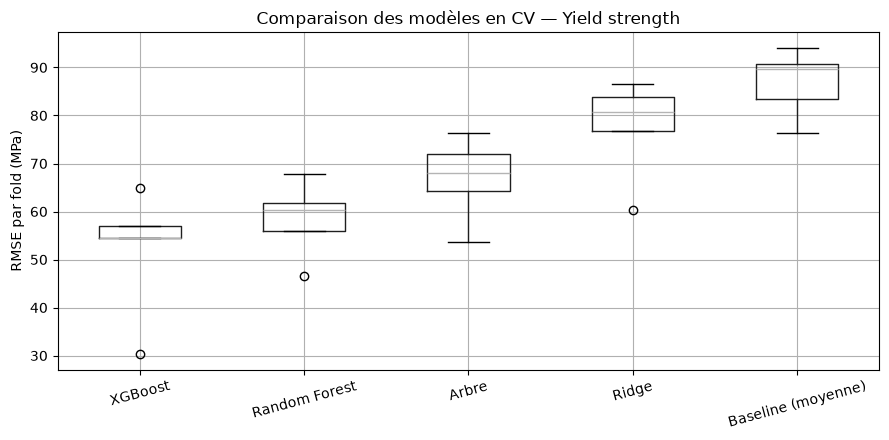

In [36]:
tableau = (pd.DataFrame({nom: resumer(s) for nom, s in registre.items()}).T
           .sort_values("moyenne"))
print(tableau.round(2))

# Boxplot des RMSE par fold
fig, ax = plt.subplots(figsize=(9, 4.5))
pd.DataFrame({nom: s["RMSE"] for nom, s in registre.items()})[tableau.index].boxplot(ax=ax)
ax.set_ylabel("RMSE par fold (MPa)")
ax.set_title(f"Comparaison des modèles en CV — {target}")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


Pour mesurer l'apport réel de l'optimisation, on ajoute au benchmark un **XGBoost avec ses hyperparamètres par défaut**, évalué avec le même prétraitement, les mêmes variables retenues et les mêmes plis de validation croisée groupée que les autres modèles. Il sert de **référence** : si les modèles optimisés ne le battent pas nettement, le réglage n'apporte rien et on préfère le modèle par défaut, plus simple.

Les **finalistes** sont ensuite les deux meilleurs modèles optimisés du benchmark (classés par RMSE moyen en validation croisée) et ce XGBoost par défaut. Seuls ces trois modèles passent à l'évaluation finale sur le jeu de test, ce qui limite le nombre de comparaisons et le risque de surestimer la performance en choisissant parmi trop de candidats.

In [38]:
# ==================================================================
# 5 bis) Choix des finalistes (aucune décision ici)
# ==================================================================
# Version par défaut : mesure le gain réel de l'optimisation
modeles["XGBoost (défaut)"] = make_pipeline(
    construire_prep(COL_NUM_RED, COL_CAT_RED), XGBRegressor(n_jobs=-1, random_state=RANDOM_STATE))
params["XGBoost (défaut)"] = {}
registre["XGBoost (défaut)"] = evaluer_cv(modeles["XGBoost (défaut)"],
                                          X_train_red, y_train, folds)

# Les 2 meilleurs modèles optimisés du benchmark + la version par défaut
top2 = [n for n in tableau.index if n in modeles][:2]
FINALISTES = top2 + ["XGBoost (défaut)"]
print("Finalistes :", FINALISTES)

Finalistes : ['XGBoost', 'Random Forest', 'XGBoost (défaut)']


In [44]:
# ==================================================================
# 5 ter) Départage des finalistes sur de NOUVEAUX découpages
# ==================================================================
# Règle pré-enregistrée, écrite AVANT le calcul :
#   le modèle retenu est celui dont le RMSE moyen sur toutes les
#   répétitions est le plus bas. Aucune exception.
SEED_REEVAL = 2026        # graine différente de RANDOM_STATE
N_REPETITIONS = 100        # 30 x 5 folds = 150 entraînements par modèle

# 1) Évaluation sur les mêmes nouveaux découpages, hyperparamètres figés
lignes = []
for r in range(N_REPETITIONS):
    folds_r = list(StratifiedGroupKFold(n_splits=5, shuffle=True,
                                        random_state=SEED_REEVAL + r)
                   .split(X_train_red, y_bins_train, groups_train))
    for nom in FINALISTES:
        s = evaluer_cv(modeles[nom], X_train_red, y_train, folds_r)
        s["modele"], s["repetition"], s["fold"] = nom, r, range(len(s))
        lignes.append(s)
reeval = pd.concat(lignes, ignore_index=True)

par_rep  = reeval.pivot_table(index="repetition", columns="modele", values="RMSE")[FINALISTES]
par_fold = reeval.pivot_table(index=["repetition", "fold"], columns="modele", values="RMSE")[FINALISTES]

In [45]:
# 2) Résumé : deux niveaux de lecture
#    - répétition -> incertitude sur la moyenne (IC 95 %)
#    - fold       -> dispersion et pire cas
m  = par_rep.mean()
se = par_rep.std() / np.sqrt(N_REPETITIONS)
resume = pd.DataFrame({
    "RMSE moyen":      m,
    "IC95 bas":        m - 1.96 * se,
    "IC95 haut":       m + 1.96 * se,
    "écart-type fold": par_fold.std(),
    "pire fold":       par_fold.max(),
    "MAE":             reeval.groupby("modele")["MAE"].mean(),
    "R2":              reeval.groupby("modele")["R2"].mean(),
}).sort_values("RMSE moyen")
print(resume.round(2).to_string())

                  RMSE moyen  IC95 bas  IC95 haut  écart-type fold  pire fold    MAE    R2
modele                                                                                    
XGBoost                54.35     53.89      54.81             9.29      76.02  38.85  0.60
XGBoost (défaut)       57.38     56.85      57.91             8.53      81.38  40.86  0.56
Random Forest          58.22     58.07      58.38             7.08      74.48  43.13  0.55


In [46]:
# 3) Application de la règle
nom_final = resume["RMSE moyen"].idxmin()
print(f"\nModèle retenu (règle pré-enregistrée) : {nom_final}")


Modèle retenu (règle pré-enregistrée) : XGBoost


In [47]:
# 4) Comparaisons appariées avec le retenu (lecture, pas décision)
comp = []
for nom in FINALISTES:
    if nom == nom_final:
        continue
    d = par_rep[nom] - par_rep[nom_final]            # > 0 : moins bon que le retenu
    se_d = d.std() / np.sqrt(len(d))
    comp.append({
        "modele": nom,
        "ecart_moyen (MPa)": d.mean(),
        "IC95_bas": d.mean() - 1.96 * se_d,
        "IC95_haut": d.mean() + 1.96 * se_d,
        "t apparié": d.mean() / se_d,
        "ecart_relatif_%": 100 * d.mean() / m[nom_final],
        "rep_gagnees_par_retenu_%": 100 * (d > 0).mean(),
        "folds_gagnes_par_retenu_%": 100 * (par_fold[nom] > par_fold[nom_final]).mean(),
    })
comp = pd.DataFrame(comp).set_index("modele")
print(comp.round(2).to_string())

                  ecart_moyen (MPa)  IC95_bas  IC95_haut  t apparié  ecart_relatif_%  rep_gagnees_par_retenu_%  folds_gagnes_par_retenu_%
modele                                                                                                                                   
Random Forest                  3.87      3.43       4.32      17.12             7.13                      92.0                       79.0
XGBoost (défaut)               3.03      2.44       3.62      10.05             5.58                      86.0                       65.0


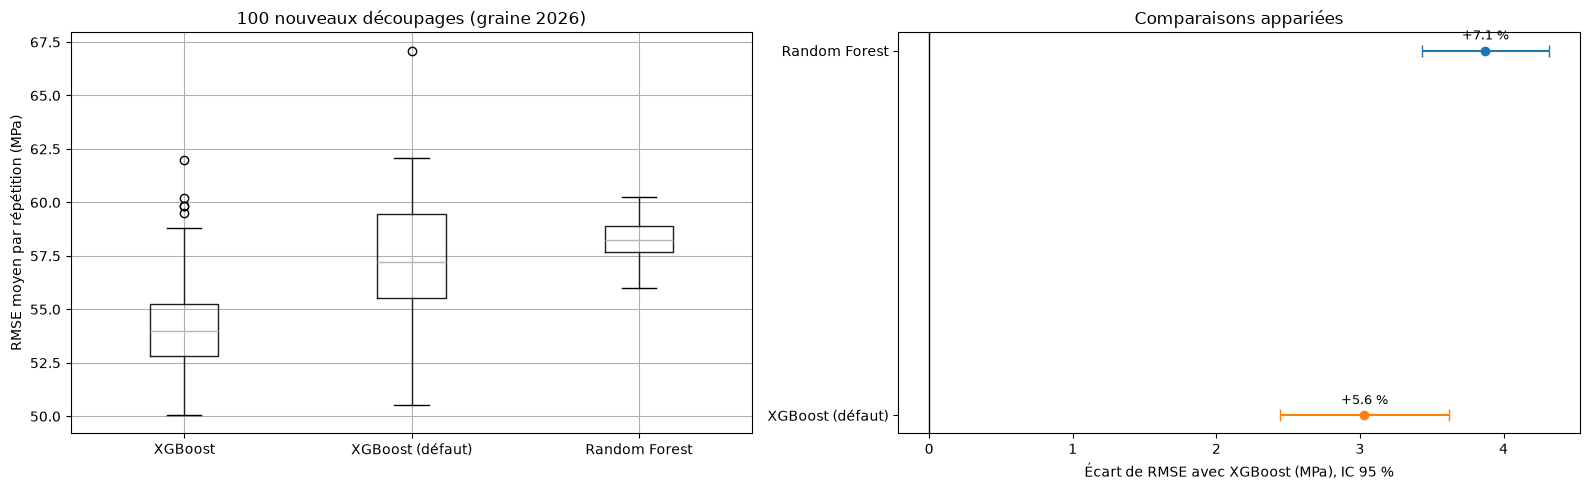

In [48]:
# 5) Représentations
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
par_rep[resume.index].boxplot(ax=ax)
ax.set_ylabel("RMSE moyen par répétition (MPa)")
ax.set_title(f"{N_REPETITIONS} nouveaux découpages (graine {SEED_REEVAL})")

ax = axes[1]
ypos = np.arange(len(comp))
for y, (nom, row) in zip(ypos, comp.iterrows()):
    ax.errorbar(row["ecart_moyen (MPa)"], y,
                xerr=[[row["ecart_moyen (MPa)"] - row["IC95_bas"]],
                      [row["IC95_haut"] - row["ecart_moyen (MPa)"]]],
                fmt="o", capsize=4)
    ax.annotate(f"{row['ecart_relatif_%']:+.1f} %", (row["ecart_moyen (MPa)"], y),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.axvline(0, c="k", lw=1)
ax.set_yticks(ypos, comp.index)
ax.invert_yaxis()
ax.set_xlabel(f"Écart de RMSE avec {nom_final} (MPa), IC 95 %")
ax.set_title("Comparaisons appariées")

plt.tight_layout()
plt.show()

Modèle final : XGBoost
Hyperparamètres : {'n_estimators': 124, 'learning_rate': 0.22038218939289875, 'max_depth': 3, 'subsample': 0.8650089137415928, 'colsample_bytree': 0.7246844304357644, 'min_child_weight': 6}

      CV (nouveaux découpages)    Test  Baseline sur le test
RMSE                    54.349  79.723               106.526
MAE                     38.846  56.736                77.348
R2                       0.604   0.439                -0.001

RMSE test = 79.7 MPa, intervalle à 95 % : [41.0 ; 108.0]
RMSE CV   = 54.3 MPa, intervalle sur les découpages : [53.9 ; 54.8]


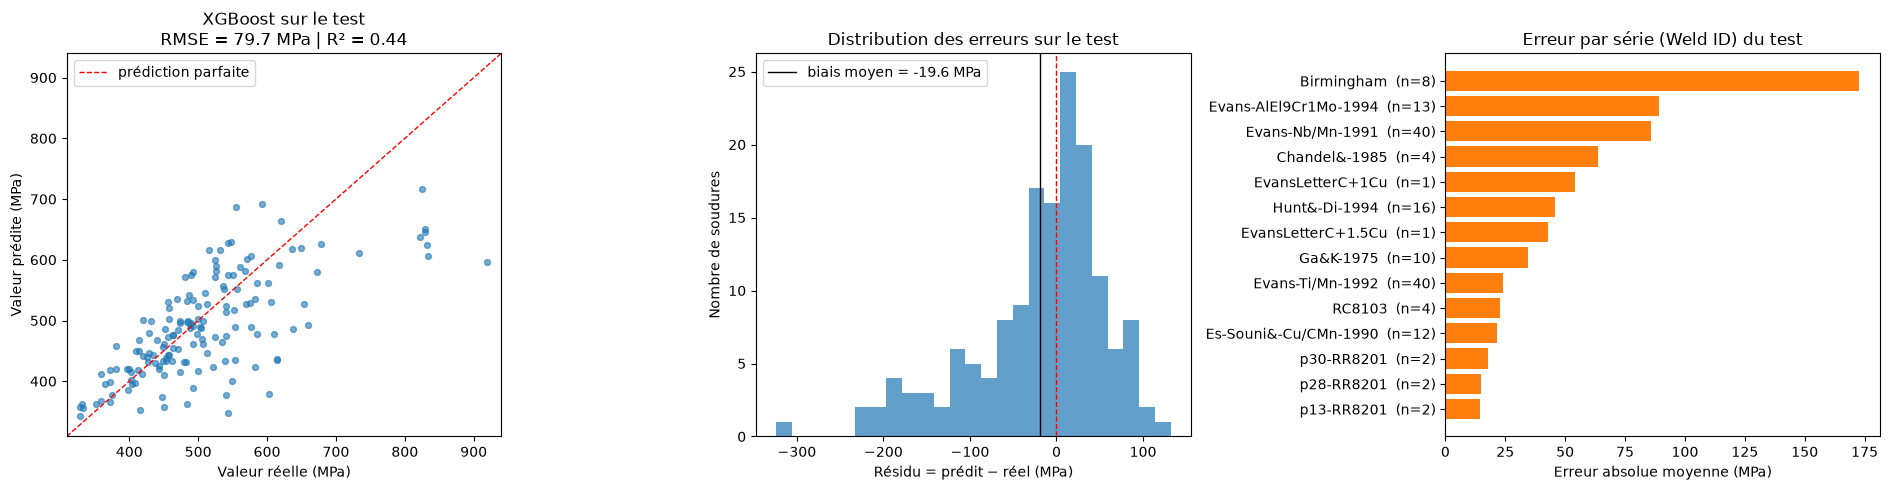

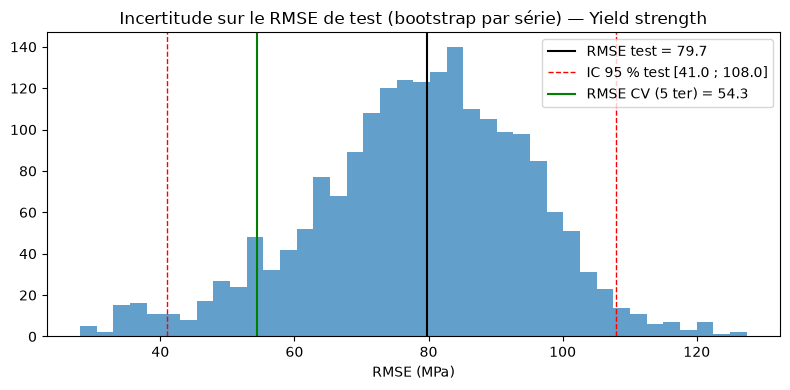

In [50]:
# ==================================================================
# 6) Évaluation finale, UNE SEULE FOIS, sur le jeu de test
#    (à lancer après la 5 ter, qui fixe nom_final)
# ==================================================================

# Scores de CV de référence : ceux des nouveaux découpages (5 ter)
cv_final = reeval[reeval["modele"] == nom_final][["RMSE", "MAE", "R2"]].mean()
rmse_cv = resume.loc[nom_final, "RMSE moyen"]
cv_bas, cv_haut = resume.loc[nom_final, "IC95 bas"], resume.loc[nom_final, "IC95 haut"]

# ------------------------------------------------------------------
# 6.1) Réentraînement du modèle retenu sur TOUT X_train, puis prédiction du test
# ------------------------------------------------------------------
modele_final = clone(modeles[nom_final])
modele_final.fit(X_train_red, y_train)
y_pred_test = modele_final.predict(X_test_red)
score_test = metriques(y_test, y_pred_test)

# Référence naïve sur le test (prédit la moyenne du train), pour situer le score
baseline = make_pipeline(construire_prep(COL_NUM_RED, COL_CAT_RED), DummyRegressor()).fit(X_train_red, y_train)
score_base = metriques(y_test, baseline.predict(X_test_red))

print(f"Modèle final : {nom_final}")
print(f"Hyperparamètres : {params[nom_final]}\n")

recap = pd.DataFrame({
    "CV (nouveaux découpages)": cv_final,
    "Test": pd.Series(score_test),
    "Baseline sur le test": pd.Series(score_base),
})
print(recap.round(3))

# ------------------------------------------------------------------
# 6.2) Intervalle de confiance du RMSE de test (bootstrap par série)
#      On tire des séries Weld ID entières avec remise, car les soudures
#      d'une même série ne sont pas indépendantes.
# ------------------------------------------------------------------
res_test = pd.DataFrame({"groupe": groups.iloc[test_idx].values,
                         "reel": y_test.values,
                         "predit": y_pred_test})
par_groupe = {g: df for g, df in res_test.groupby("groupe")}
noms_groupes = list(par_groupe)

rng = np.random.default_rng(RANDOM_STATE)
boot_rmse = []
for _ in range(2000):
    tirage = rng.choice(noms_groupes, size=len(noms_groupes), replace=True)
    ech = pd.concat([par_groupe[g] for g in tirage])
    boot_rmse.append(root_mean_squared_error(ech["reel"], ech["predit"]))
ic_bas, ic_haut = np.percentile(boot_rmse, [2.5, 97.5])

print(f"\nRMSE test = {score_test['RMSE']:.1f} MPa, intervalle à 95 % : [{ic_bas:.1f} ; {ic_haut:.1f}]")
print(f"RMSE CV   = {rmse_cv:.1f} MPa, intervalle sur les découpages : [{cv_bas:.1f} ; {cv_haut:.1f}]")

# ------------------------------------------------------------------
# 6.3) Représentations
# ------------------------------------------------------------------
res_test["residu"] = res_test["predit"] - res_test["reel"]
err_series = (res_test.assign(erreur_abs=res_test["residu"].abs())
              .groupby("groupe")["erreur_abs"].agg(["mean", "size"])
              .sort_values("mean", ascending=False))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# a) Prédit vs réel
ax = axes[0]
lims = [min(res_test["reel"].min(), res_test["predit"].min()) - 20,
        max(res_test["reel"].max(), res_test["predit"].max()) + 20]
ax.scatter(res_test["reel"], res_test["predit"], s=18, alpha=0.6)
ax.plot(lims, lims, "r--", lw=1, label="prédiction parfaite")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Valeur réelle (MPa)")
ax.set_ylabel("Valeur prédite (MPa)")
ax.set_title(f"{nom_final} sur le test\nRMSE = {score_test['RMSE']:.1f} MPa | R² = {score_test['R2']:.2f}")
ax.legend()

# b) Distribution des résidus
ax = axes[1]
ax.hist(res_test["residu"], bins=25, color="#1f77b4", alpha=0.7)
ax.axvline(0, c="r", ls="--", lw=1)
ax.axvline(res_test["residu"].mean(), c="k", lw=1,
           label=f"biais moyen = {res_test['residu'].mean():.1f} MPa")
ax.set_xlabel("Résidu = prédit − réel (MPa)")
ax.set_ylabel("Nombre de soudures")
ax.set_title("Distribution des erreurs sur le test")
ax.legend()

# c) Erreur par série du test
ax = axes[2]
ax.barh(err_series.index + "  (n=" + err_series["size"].astype(str) + ")",
        err_series["mean"], color="#ff7f0e")
ax.invert_yaxis()
ax.set_xlabel("Erreur absolue moyenne (MPa)")
ax.set_title("Erreur par série (Weld ID) du test")

plt.tight_layout()
plt.show()

# d) Distribution bootstrap du RMSE de test, comparée à la CV
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(boot_rmse, bins=40, color="#1f77b4", alpha=0.7)
ax.axvline(score_test["RMSE"], c="k", lw=1.5, label=f"RMSE test = {score_test['RMSE']:.1f}")
ax.axvline(ic_bas, c="r", ls="--", lw=1, label=f"IC 95 % test [{ic_bas:.1f} ; {ic_haut:.1f}]")
ax.axvline(ic_haut, c="r", ls="--", lw=1)
ax.axvline(rmse_cv, c="g", lw=1.5, label=f"RMSE CV (5 ter) = {rmse_cv:.1f}")
ax.set_xlabel("RMSE (MPa)")
ax.set_title(f"Incertitude sur le RMSE de test (bootstrap par série) — {target}")
ax.legend()
plt.tight_layout()
plt.show()

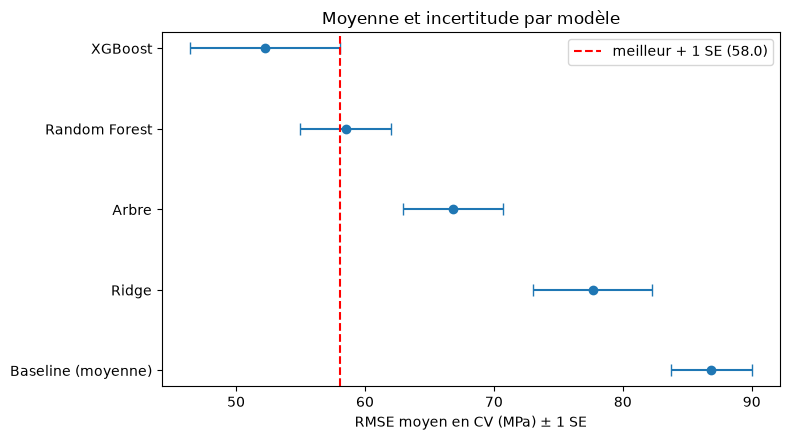

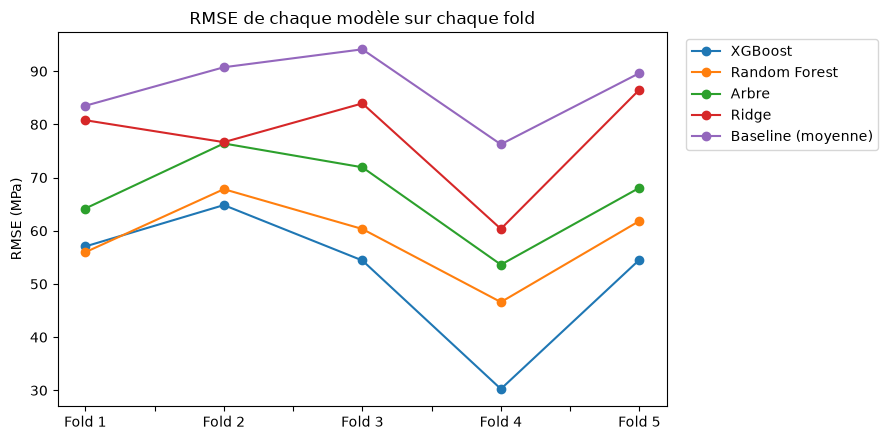

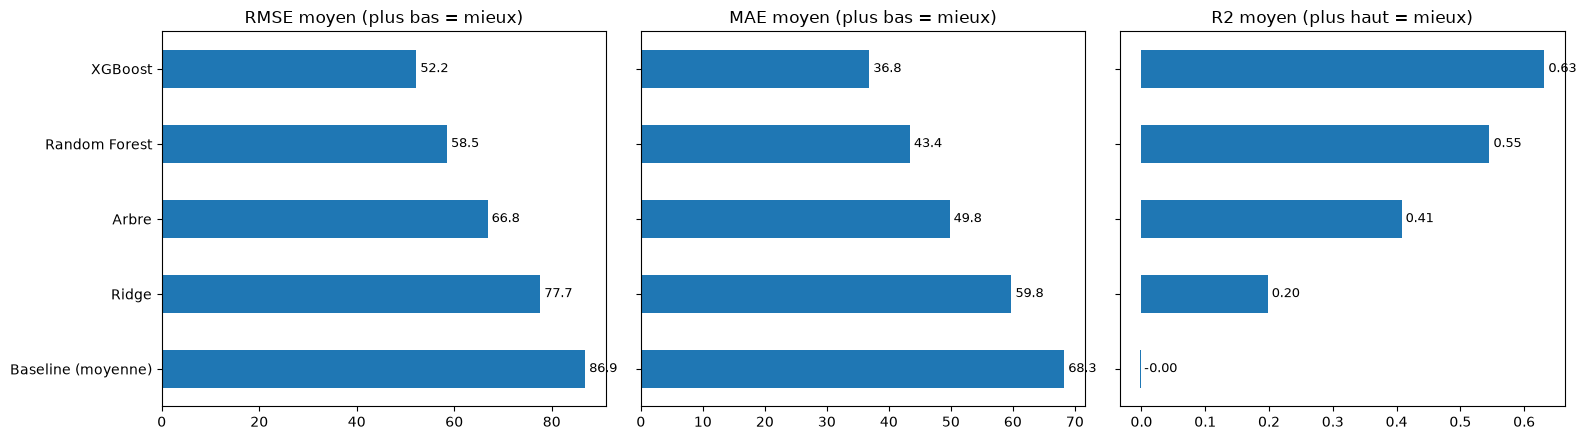

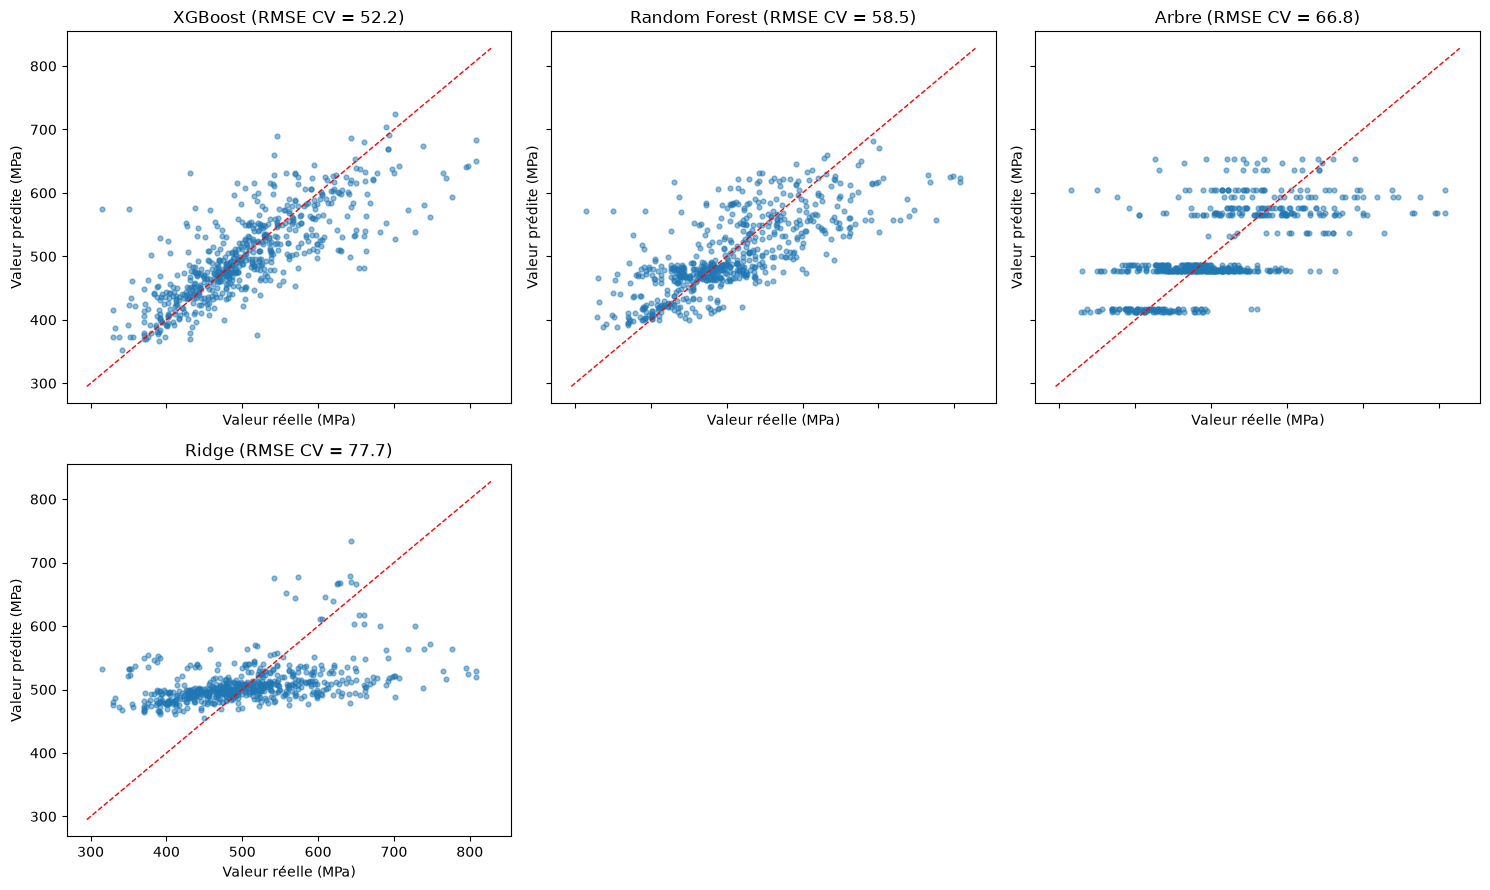

In [51]:
t = tableau.sort_values("moyenne")
noms_modeles = [n for n in t.index if n in modeles]   # sans la baseline

# ------------------------------------------------------------------
# A) RMSE moyen ± SE, avec le seuil de la règle 1-SE
# ------------------------------------------------------------------
best = t.loc[noms_modeles[0]]
fig, ax = plt.subplots(figsize=(8, 4.5))
ypos = np.arange(len(t))
ax.errorbar(t["moyenne"], ypos, xerr=t["SE"], fmt="o", capsize=4, color="#1f77b4")
ax.axvline(best["moyenne"] + best["SE"], ls="--", c="red",
           label=f"meilleur + 1 SE ({best['moyenne'] + best['SE']:.1f})")
ax.set_yticks(ypos, t.index)
ax.invert_yaxis()
ax.set_xlabel("RMSE moyen en CV (MPa) ± 1 SE")
ax.set_title("Moyenne et incertitude par modèle")
ax.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# B) RMSE fold par fold : le classement est-il le même partout ?
# ------------------------------------------------------------------
fold_rmse = pd.DataFrame({nom: s["RMSE"] for nom, s in registre.items()})[t.index]
fold_rmse.index = [f"Fold {i + 1}" for i in range(len(fold_rmse))]

fig, ax = plt.subplots(figsize=(9, 4.5))
fold_rmse.plot(marker="o", ax=ax)
ax.set_ylabel("RMSE (MPa)")
ax.set_title("RMSE de chaque modèle sur chaque fold")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# C) Les trois métriques côte à côte
# ------------------------------------------------------------------
moyennes = pd.DataFrame({nom: s.mean() for nom, s in registre.items()}).T.loc[t.index]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (m, sens) in zip(axes, [("RMSE", "plus bas = mieux"),
                                ("MAE", "plus bas = mieux"),
                                ("R2", "plus haut = mieux")]):
    moyennes[m].plot.barh(ax=ax, color="#1f77b4")
    for i, v in enumerate(moyennes[m]):
        ax.text(v, i, f" {v:.2f}" if m == "R2" else f" {v:.1f}", va="center", fontsize=9)
    ax.set_title(f"{m} moyen ({sens})")
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# D) Prédictions hors-fold vs valeurs réelles, pour chaque modèle
#    (chaque soudure est prédite par le modèle qui ne l'a pas vue)
# ------------------------------------------------------------------
oof = {nom: cross_val_predict(modeles[nom], X_train_red, y_train, cv=folds)
       for nom in noms_modeles}

n = len(noms_modeles)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows),
                         sharex=True, sharey=True)
lims = [y_train.min() - 20, y_train.max() + 20]
for ax, nom in zip(axes.flat, noms_modeles):
    ax.scatter(y_train, oof[nom], s=12, alpha=0.5)
    ax.plot(lims, lims, "r--", lw=1)                       # prédiction parfaite
    ax.set_title(f"{nom} (RMSE CV = {t.loc[nom, 'moyenne']:.1f})")
    ax.set_xlabel("Valeur réelle (MPa)")
    ax.set_ylabel("Valeur prédite (MPa)")
for ax in axes.flat[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()


#### B. Méthode avec sélection de variables

In [63]:
# ==================================================================
# 0) Données : on applique les choix des étapes précédentes
# ==================================================================
# Colonnes d'origine supprimées par le filtre de corrélation
# (les colonnes one-hot éventuellement supprimées sont ignorées : elles sont redondantes entre elles)
cols_gardees = best_feats
cols_supprimees = [f for f in X_train_fe.columns if f not in best_feats]
print("Colonnes supprimées :", cols_supprimees)

X_train_red = X_train_fe.drop(columns=cols_supprimees)
X_test_red = X_test_fe.drop(columns=cols_supprimees)
COL_NUM_RED = [c for c in COL_NUM if c not in cols_supprimees]
COL_CAT_RED = [c for c in COL_CAT if c not in cols_supprimees]

# Folds : les MÊMES pour tous les modèles, groupés sur Weld ID, calculés sur tout X_train
groups_train = groups.iloc[train_idx]
y_bins_train = y_bins.iloc[train_idx]
folds = list(sgkf.split(X_train_red, y_bins_train, groups_train))

Colonnes supprimées : ['Silicon concentration', 'Manganese concentration', 'Sulphur concentration', 'Phosphorus concentration', 'Nickel concentration', 'Chromium concentration', 'Copper concentration', 'Nitrogen concentration', 'Aluminium concentration', 'Voltage', 'Type of weld']


In [65]:

registre = {}   # nom du modèle -> DataFrame des scores par fold

# ==================================================================
# 4) Réglage de chaque modèle avec Optuna (même budget pour tous)
# ==================================================================

optuna.logging.set_verbosity(optuna.logging.WARNING)

# Référence naïve : prédit toujours la moyenne (rien à régler)
registre["Baseline (moyenne)"] = evaluer_cv(make_pipeline(construire_prep(COL_NUM_RED, COL_CAT_RED), DummyRegressor()),
                                            X_train_red, y_train, folds)

modeles, params = {}, {}

# Régression linéaire classique : rien à régler, évaluation directe
lin = make_pipeline(construire_prep(COL_NUM_RED, COL_CAT_RED), StandardScaler(), LinearRegression())
registre["Régression linéaire"] = evaluer_cv(lin, X_train_red, y_train, folds)
modeles["Régression linéaire"], params["Régression linéaire"] = lin, {}

# Modèles avec hyperparamètres réglés par Optuna
for nom, fn in [("Ridge", ridge), ("Arbre", arbre),
                ("Random Forest", random_forest), ("XGBoost", xgboost)]:
    modeles[nom], params[nom] = optimiser(nom, fn,X_train_fe,y_train, construire_prep(COL_NUM_RED, COL_CAT_RED), n_trials=n_TRIALS)



Ridge : 65/100 essais indiscernables, retenu n°78 (80.7 vs meilleur 80.7)
Arbre : 46/100 essais indiscernables, retenu n°78 (62.9 vs meilleur 61.6)
Random Forest : 92/100 essais indiscernables, retenu n°29 (52.8 vs meilleur 50.7)
XGBoost : 71/100 essais indiscernables, retenu n°3 (49.6 vs meilleur 47.0)


                     moyenne  ecart_type     SE  pire_fold
XGBoost                49.58        7.70   3.44      56.89
Random Forest          52.80        7.51   3.36      59.34
Arbre                  62.87        4.83   2.16      67.30
Ridge                  80.73        7.78   3.48      87.31
Baseline (moyenne)     86.86        7.06   3.16      94.12
Régression linéaire   103.92       26.99  12.07     127.16


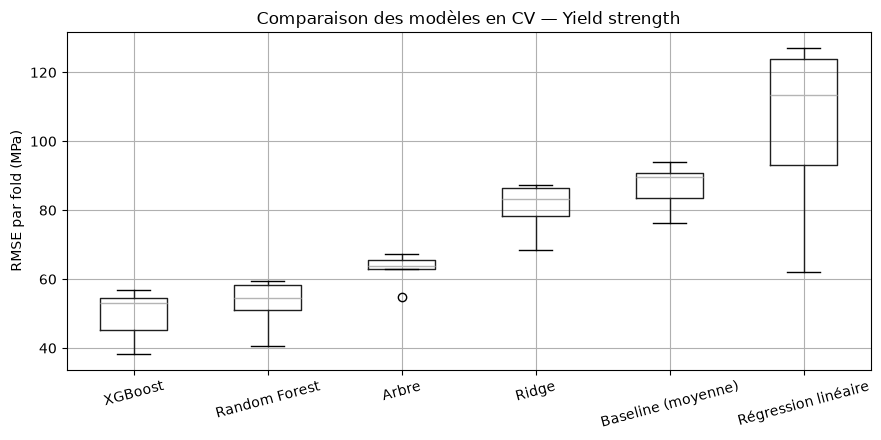

In [66]:

# ==================================================================
# 5) Comparaison des modèles réglés
# ==================================================================
tableau = (pd.DataFrame({nom: resumer(s) for nom, s in registre.items()}).T
           .sort_values("moyenne"))
print(tableau.round(2))

# Boxplot des RMSE par fold
fig, ax = plt.subplots(figsize=(9, 4.5))
pd.DataFrame({nom: s["RMSE"] for nom, s in registre.items()})[tableau.index].boxplot(ax=ax)
ax.set_ylabel("RMSE par fold (MPa)")
ax.set_title(f"Comparaison des modèles en CV — {target}")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [68]:
# ==================================================================
# 5 bis) Choix des finalistes (aucune décision ici)
# ==================================================================
# Version par défaut : mesure le gain réel de l'optimisation
modeles["XGBoost (défaut)"] = make_pipeline(
    construire_prep(COL_NUM_RED, COL_CAT_RED), XGBRegressor(n_jobs=-1, random_state=RANDOM_STATE))
params["XGBoost (défaut)"] = {}
registre["XGBoost (défaut)"] = evaluer_cv(modeles["XGBoost (défaut)"],
                                          X_train_red, y_train, folds)

# Les 2 meilleurs modèles optimisés du benchmark + la version par défaut
top2 = [n for n in tableau.index if n in modeles][:2]
FINALISTES = top2 + ["XGBoost (défaut)"]
print("Finalistes :", FINALISTES)

Finalistes : ['XGBoost', 'Random Forest', 'XGBoost (défaut)']


                  RMSE moyen  IC95 bas  IC95 haut  écart-type fold  pire fold    MAE    R2
modele                                                                                    
XGBoost                49.42     48.97      49.88             7.81      71.82  36.14  0.67
Random Forest          53.05     52.78      53.32             8.05      70.82  38.72  0.62
XGBoost (défaut)       54.39     53.49      55.28             9.68      80.39  39.69  0.59

Modèle retenu (règle pré-enregistrée) : XGBoost
                  ecart_moyen (MPa)  IC95_bas  IC95_haut  t apparié  ecart_relatif_%  rep_gagnees_par_retenu_%  folds_gagnes_par_retenu_%
modele                                                                                                                                   
Random Forest                  3.62      3.25       4.00      18.94             7.33                     100.0                       92.0
XGBoost (défaut)               4.96      4.15       5.77      12.07            10.

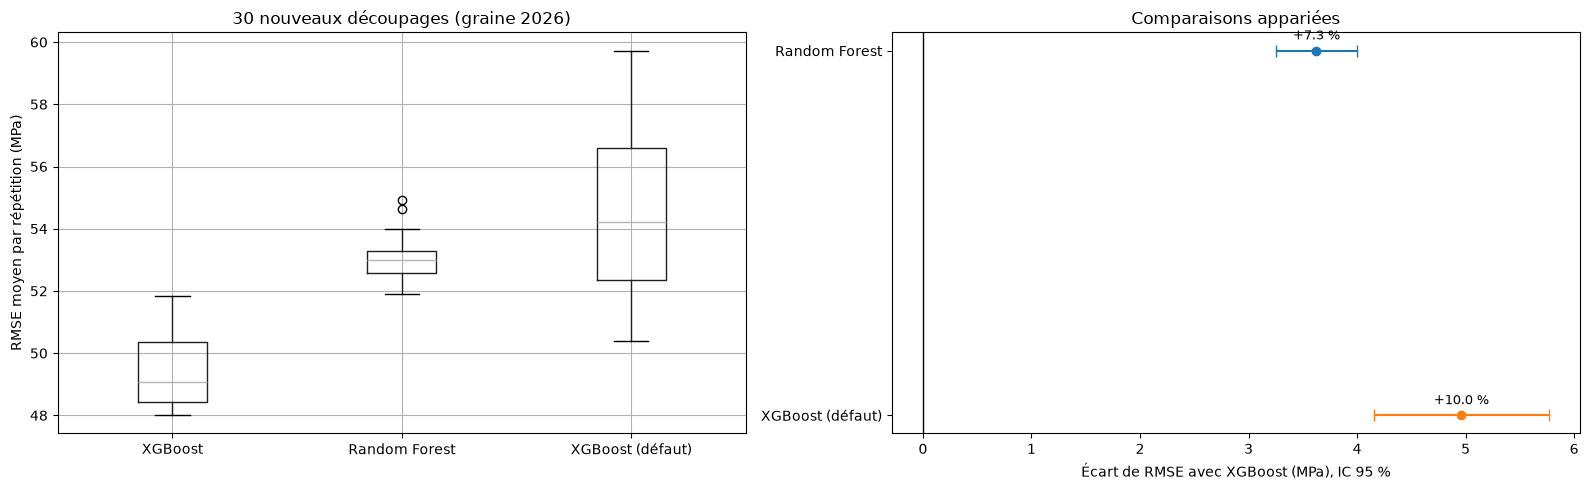

In [69]:
# ==================================================================
# 5 ter) Départage des finalistes sur de NOUVEAUX découpages
# ==================================================================
# Règle pré-enregistrée, écrite AVANT le calcul :
#   le modèle retenu est celui dont le RMSE moyen sur toutes les
#   répétitions est le plus bas. Aucune exception.
SEED_REEVAL = 2026        # graine différente de RANDOM_STATE
N_REPETITIONS = 30        # 30 x 5 folds = 150 entraînements par modèle

# 1) Évaluation sur les mêmes nouveaux découpages, hyperparamètres figés
lignes = []
for r in range(N_REPETITIONS):
    folds_r = list(StratifiedGroupKFold(n_splits=5, shuffle=True,
                                        random_state=SEED_REEVAL + r)
                   .split(X_train_red, y_bins_train, groups_train))
    for nom in FINALISTES:
        s = evaluer_cv(modeles[nom], X_train_red, y_train, folds_r)
        s["modele"], s["repetition"], s["fold"] = nom, r, range(len(s))
        lignes.append(s)
reeval = pd.concat(lignes, ignore_index=True)

par_rep  = reeval.pivot_table(index="repetition", columns="modele", values="RMSE")[FINALISTES]
par_fold = reeval.pivot_table(index=["repetition", "fold"], columns="modele", values="RMSE")[FINALISTES]

# 2) Résumé : deux niveaux de lecture
#    - répétition -> incertitude sur la moyenne (IC 95 %)
#    - fold       -> dispersion et pire cas
m  = par_rep.mean()
se = par_rep.std() / np.sqrt(N_REPETITIONS)
resume = pd.DataFrame({
    "RMSE moyen":      m,
    "IC95 bas":        m - 1.96 * se,
    "IC95 haut":       m + 1.96 * se,
    "écart-type fold": par_fold.std(),
    "pire fold":       par_fold.max(),
    "MAE":             reeval.groupby("modele")["MAE"].mean(),
    "R2":              reeval.groupby("modele")["R2"].mean(),
}).sort_values("RMSE moyen")
print(resume.round(2).to_string())

# 3) Application de la règle
nom_final = resume["RMSE moyen"].idxmin()
print(f"\nModèle retenu (règle pré-enregistrée) : {nom_final}")

# 4) Comparaisons appariées avec le retenu (lecture, pas décision)
comp = []
for nom in FINALISTES:
    if nom == nom_final:
        continue
    d = par_rep[nom] - par_rep[nom_final]            # > 0 : moins bon que le retenu
    se_d = d.std() / np.sqrt(len(d))
    comp.append({
        "modele": nom,
        "ecart_moyen (MPa)": d.mean(),
        "IC95_bas": d.mean() - 1.96 * se_d,
        "IC95_haut": d.mean() + 1.96 * se_d,
        "t apparié": d.mean() / se_d,
        "ecart_relatif_%": 100 * d.mean() / m[nom_final],
        "rep_gagnees_par_retenu_%": 100 * (d > 0).mean(),
        "folds_gagnes_par_retenu_%": 100 * (par_fold[nom] > par_fold[nom_final]).mean(),
    })
comp = pd.DataFrame(comp).set_index("modele")
print(comp.round(2).to_string())

# 5) Représentations
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
par_rep[resume.index].boxplot(ax=ax)
ax.set_ylabel("RMSE moyen par répétition (MPa)")
ax.set_title(f"{N_REPETITIONS} nouveaux découpages (graine {SEED_REEVAL})")

ax = axes[1]
ypos = np.arange(len(comp))
for y, (nom, row) in zip(ypos, comp.iterrows()):
    ax.errorbar(row["ecart_moyen (MPa)"], y,
                xerr=[[row["ecart_moyen (MPa)"] - row["IC95_bas"]],
                      [row["IC95_haut"] - row["ecart_moyen (MPa)"]]],
                fmt="o", capsize=4)
    ax.annotate(f"{row['ecart_relatif_%']:+.1f} %", (row["ecart_moyen (MPa)"], y),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.axvline(0, c="k", lw=1)
ax.set_yticks(ypos, comp.index)
ax.invert_yaxis()
ax.set_xlabel(f"Écart de RMSE avec {nom_final} (MPa), IC 95 %")
ax.set_title("Comparaisons appariées")

plt.tight_layout()
plt.show()

Modèle final : XGBoost
Hyperparamètres : {'n_estimators': 402, 'learning_rate': 0.02692655251486473, 'max_depth': 6, 'subsample': 0.6557975442608167, 'colsample_bytree': 0.7168578594140873, 'min_child_weight': 4}

      CV (nouveaux découpages)    Test  Baseline sur le test
RMSE                    49.425  80.901               106.526
MAE                     36.144  55.104                77.348
R2                       0.667   0.423                -0.001

RMSE test = 80.9 MPa, intervalle à 95 % : [36.5 ; 111.7]
RMSE CV   = 49.4 MPa, intervalle sur les découpages : [49.0 ; 49.9]


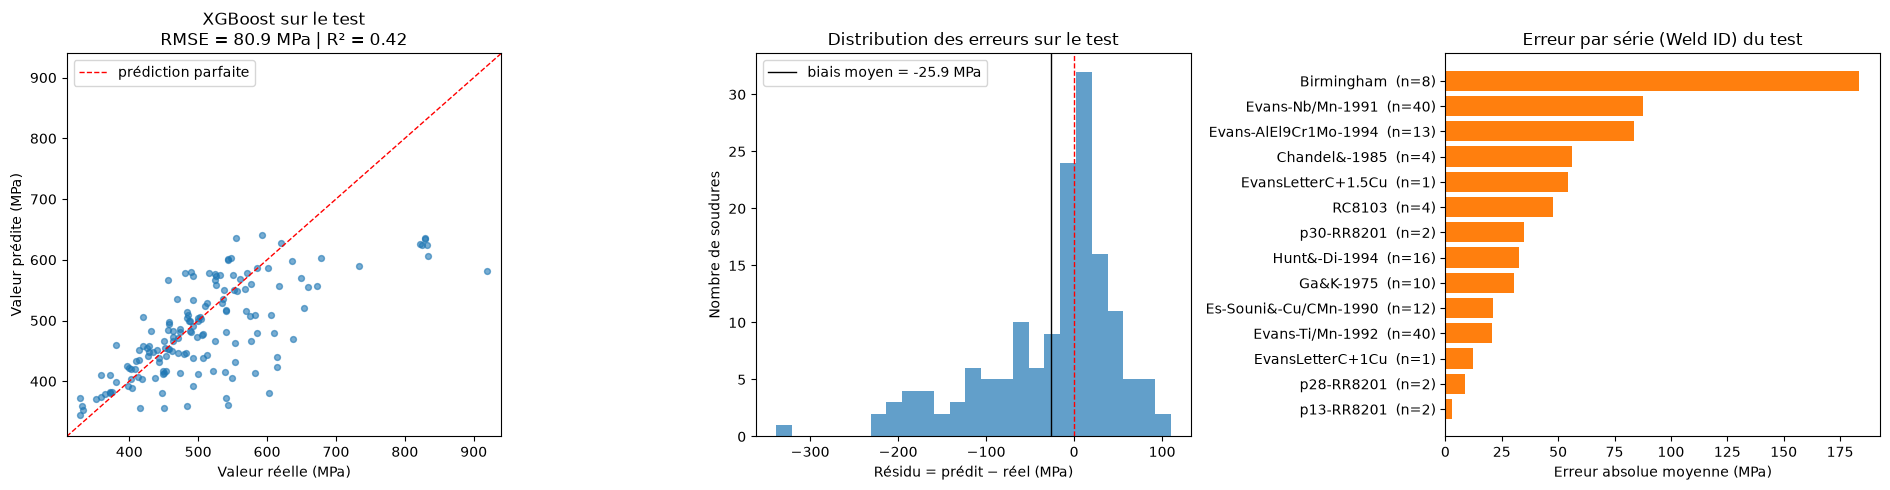

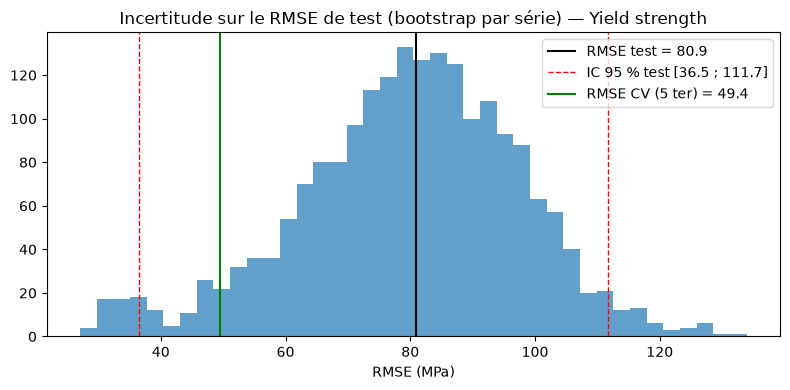

In [71]:
# ==================================================================
# 6) Évaluation finale, UNE SEULE FOIS, sur le jeu de test
#    (à lancer après la 5 ter, qui fixe nom_final)
# ==================================================================

# Scores de CV de référence : ceux des nouveaux découpages (5 ter)
cv_final = reeval[reeval["modele"] == nom_final][["RMSE", "MAE", "R2"]].mean()
rmse_cv = resume.loc[nom_final, "RMSE moyen"]
cv_bas, cv_haut = resume.loc[nom_final, "IC95 bas"], resume.loc[nom_final, "IC95 haut"]

# ------------------------------------------------------------------
# 6.1) Réentraînement du modèle retenu sur TOUT X_train, puis prédiction du test
# ------------------------------------------------------------------
modele_final = clone(modeles[nom_final])
modele_final.fit(X_train_red, y_train)
y_pred_test = modele_final.predict(X_test_red)
score_test = metriques(y_test, y_pred_test)

# Référence naïve sur le test (prédit la moyenne du train), pour situer le score
baseline = make_pipeline(construire_prep(COL_NUM_RED, COL_CAT_RED), DummyRegressor()).fit(X_train_red, y_train)
score_base = metriques(y_test, baseline.predict(X_test_red))

print(f"Modèle final : {nom_final}")
print(f"Hyperparamètres : {params[nom_final]}\n")

recap = pd.DataFrame({
    "CV (nouveaux découpages)": cv_final,
    "Test": pd.Series(score_test),
    "Baseline sur le test": pd.Series(score_base),
})
print(recap.round(3))

# ------------------------------------------------------------------
# 6.2) Intervalle de confiance du RMSE de test (bootstrap par série)
#      On tire des séries Weld ID entières avec remise, car les soudures
#      d'une même série ne sont pas indépendantes.
# ------------------------------------------------------------------
res_test = pd.DataFrame({"groupe": groups.iloc[test_idx].values,
                         "reel": y_test.values,
                         "predit": y_pred_test})
par_groupe = {g: df for g, df in res_test.groupby("groupe")}
noms_groupes = list(par_groupe)

rng = np.random.default_rng(RANDOM_STATE)
boot_rmse = []
for _ in range(2000):
    tirage = rng.choice(noms_groupes, size=len(noms_groupes), replace=True)
    ech = pd.concat([par_groupe[g] for g in tirage])
    boot_rmse.append(root_mean_squared_error(ech["reel"], ech["predit"]))
ic_bas, ic_haut = np.percentile(boot_rmse, [2.5, 97.5])

print(f"\nRMSE test = {score_test['RMSE']:.1f} MPa, intervalle à 95 % : [{ic_bas:.1f} ; {ic_haut:.1f}]")
print(f"RMSE CV   = {rmse_cv:.1f} MPa, intervalle sur les découpages : [{cv_bas:.1f} ; {cv_haut:.1f}]")

# ------------------------------------------------------------------
# 6.3) Représentations
# ------------------------------------------------------------------
res_test["residu"] = res_test["predit"] - res_test["reel"]
err_series = (res_test.assign(erreur_abs=res_test["residu"].abs())
              .groupby("groupe")["erreur_abs"].agg(["mean", "size"])
              .sort_values("mean", ascending=False))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# a) Prédit vs réel
ax = axes[0]
lims = [min(res_test["reel"].min(), res_test["predit"].min()) - 20,
        max(res_test["reel"].max(), res_test["predit"].max()) + 20]
ax.scatter(res_test["reel"], res_test["predit"], s=18, alpha=0.6)
ax.plot(lims, lims, "r--", lw=1, label="prédiction parfaite")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Valeur réelle (MPa)")
ax.set_ylabel("Valeur prédite (MPa)")
ax.set_title(f"{nom_final} sur le test\nRMSE = {score_test['RMSE']:.1f} MPa | R² = {score_test['R2']:.2f}")
ax.legend()

# b) Distribution des résidus
ax = axes[1]
ax.hist(res_test["residu"], bins=25, color="#1f77b4", alpha=0.7)
ax.axvline(0, c="r", ls="--", lw=1)
ax.axvline(res_test["residu"].mean(), c="k", lw=1,
           label=f"biais moyen = {res_test['residu'].mean():.1f} MPa")
ax.set_xlabel("Résidu = prédit − réel (MPa)")
ax.set_ylabel("Nombre de soudures")
ax.set_title("Distribution des erreurs sur le test")
ax.legend()

# c) Erreur par série du test
ax = axes[2]
ax.barh(err_series.index + "  (n=" + err_series["size"].astype(str) + ")",
        err_series["mean"], color="#ff7f0e")
ax.invert_yaxis()
ax.set_xlabel("Erreur absolue moyenne (MPa)")
ax.set_title("Erreur par série (Weld ID) du test")

plt.tight_layout()
plt.show()

# d) Distribution bootstrap du RMSE de test, comparée à la CV
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(boot_rmse, bins=40, color="#1f77b4", alpha=0.7)
ax.axvline(score_test["RMSE"], c="k", lw=1.5, label=f"RMSE test = {score_test['RMSE']:.1f}")
ax.axvline(ic_bas, c="r", ls="--", lw=1, label=f"IC 95 % test [{ic_bas:.1f} ; {ic_haut:.1f}]")
ax.axvline(ic_haut, c="r", ls="--", lw=1)
ax.axvline(rmse_cv, c="g", lw=1.5, label=f"RMSE CV (5 ter) = {rmse_cv:.1f}")
ax.set_xlabel("RMSE (MPa)")
ax.set_title(f"Incertitude sur le RMSE de test (bootstrap par série) — {target}")
ax.legend()
plt.tight_layout()
plt.show()

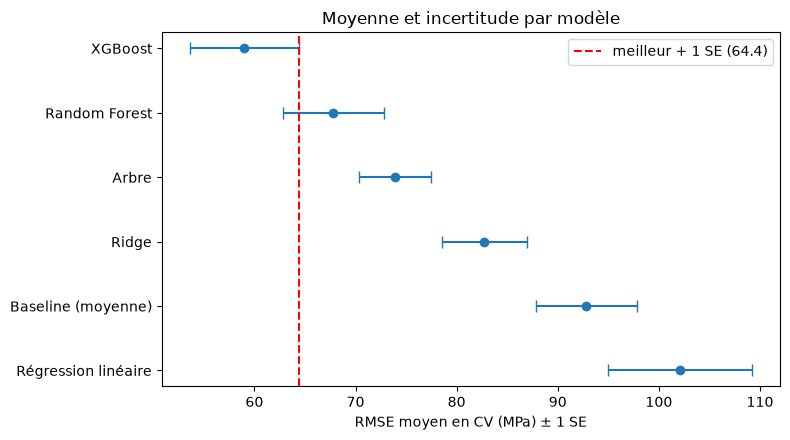

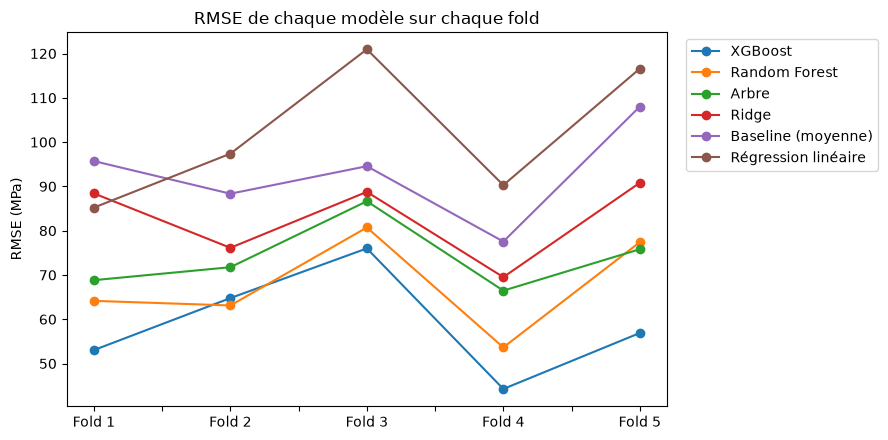

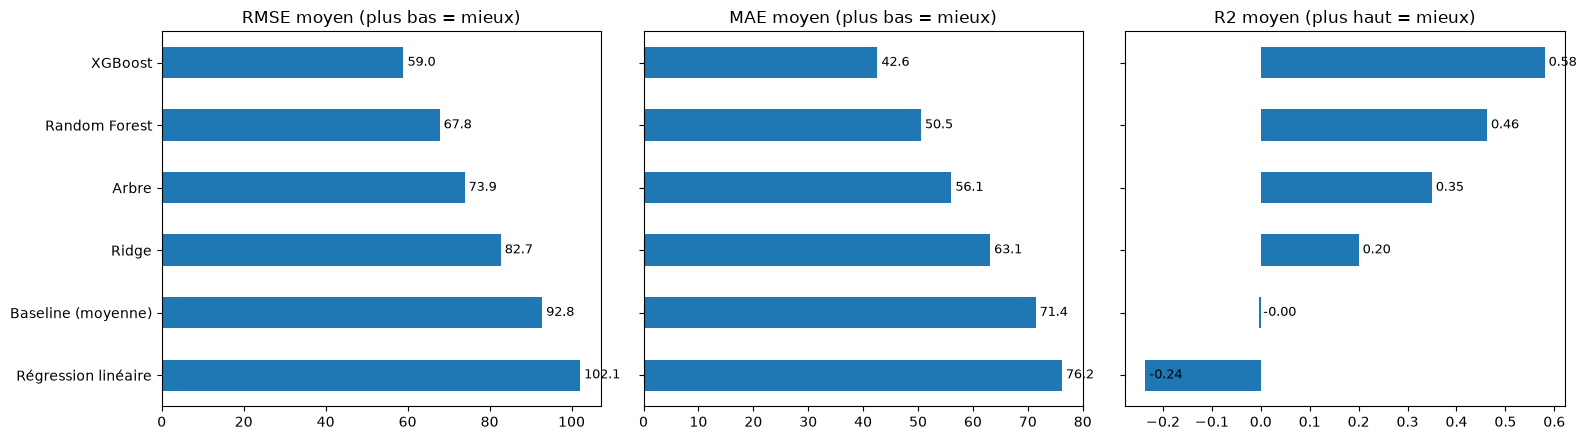

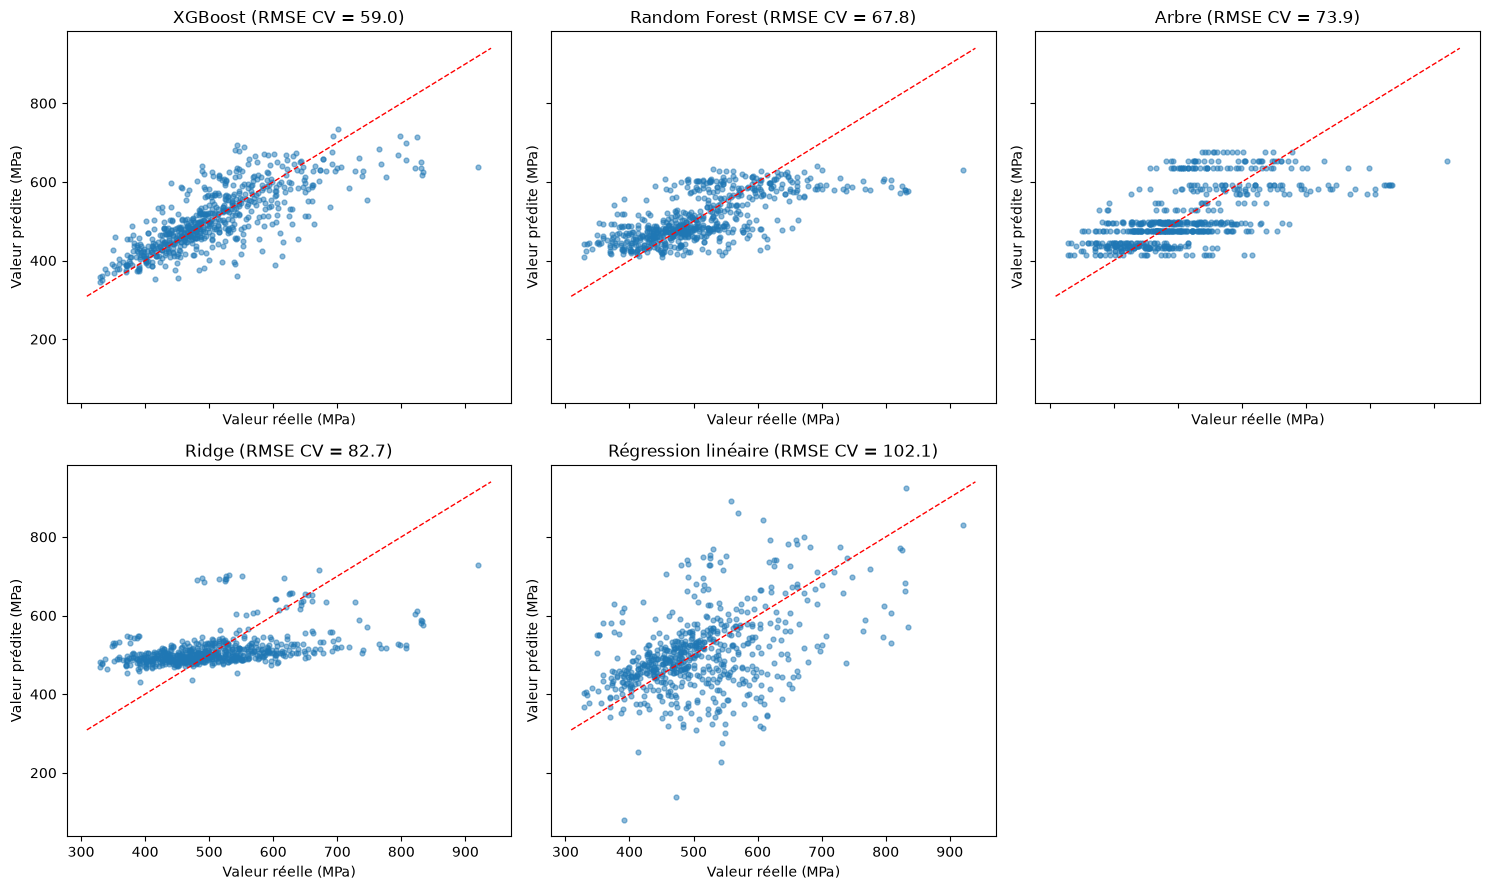

In [ ]:
t = tableau.sort_values("moyenne")
noms_modeles = [n for n in t.index if n in modeles]   # sans la baseline

# ------------------------------------------------------------------
# A) RMSE moyen ± SE, avec le seuil de la règle 1-SE
# ------------------------------------------------------------------
best = t.loc[noms_modeles[0]]
fig, ax = plt.subplots(figsize=(8, 4.5))
ypos = np.arange(len(t))
ax.errorbar(t["moyenne"], ypos, xerr=t["SE"], fmt="o", capsize=4, color="#1f77b4")
ax.axvline(best["moyenne"] + best["SE"], ls="--", c="red",
           label=f"meilleur + 1 SE ({best['moyenne'] + best['SE']:.1f})")
ax.set_yticks(ypos, t.index)
ax.invert_yaxis()
ax.set_xlabel("RMSE moyen en CV (MPa) ± 1 SE")
ax.set_title("Moyenne et incertitude par modèle")
ax.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# B) RMSE fold par fold : le classement est-il le même partout ?
# ------------------------------------------------------------------
fold_rmse = pd.DataFrame({nom: s["RMSE"] for nom, s in registre.items()})[t.index]
fold_rmse.index = [f"Fold {i + 1}" for i in range(len(fold_rmse))]

fig, ax = plt.subplots(figsize=(9, 4.5))
fold_rmse.plot(marker="o", ax=ax)
ax.set_ylabel("RMSE (MPa)")
ax.set_title("RMSE de chaque modèle sur chaque fold")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# C) Les trois métriques côte à côte
# ------------------------------------------------------------------
moyennes = pd.DataFrame({nom: s.mean() for nom, s in registre.items()}).T.loc[t.index]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (m, sens) in zip(axes, [("RMSE", "plus bas = mieux"),
                                ("MAE", "plus bas = mieux"),
                                ("R2", "plus haut = mieux")]):
    moyennes[m].plot.barh(ax=ax, color="#1f77b4")
    for i, v in enumerate(moyennes[m]):
        ax.text(v, i, f" {v:.2f}" if m == "R2" else f" {v:.1f}", va="center", fontsize=9)
    ax.set_title(f"{m} moyen ({sens})")
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# D) Prédictions hors-fold vs valeurs réelles, pour chaque modèle
#    (chaque soudure est prédite par le modèle qui ne l'a pas vue)
# ------------------------------------------------------------------
oof = {nom: cross_val_predict(modeles[nom], X_train_red, y_train, cv=folds)
       for nom in noms_modeles}

n = len(noms_modeles)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows),
                         sharex=True, sharey=True)
lims = [y_train.min() - 20, y_train.max() + 20]
for ax, nom in zip(axes.flat, noms_modeles):
    ax.scatter(y_train, oof[nom], s=12, alpha=0.5)
    ax.plot(lims, lims, "r--", lw=1)                       # prédiction parfaite
    ax.set_title(f"{nom} (RMSE CV = {t.loc[nom, 'moyenne']:.1f})")
    ax.set_xlabel("Valeur réelle (MPa)")
    ax.set_ylabel("Valeur prédite (MPa)")
for ax in axes.flat[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()


## Conclusion

Dans le cadre de ce notebook, nous avons pu tester la prédiction et établir une pipeline de prédiction pour une cible en particulier `Yield strength`. Cette méthode peut être adapté pour d'autre cible, et même des classifications si besoin. 

Cependant, nous avons remarquer un problème fonctionnelle dans le cadre du projet. On a au total 5 cibles à prédire, mais aucune qui indique directement la qualité de la soudure et la prédiction de ce notebook n'est pas du tout convainquante. C'est pour cela, dans le prochain notebook nous allons chercher à créer une cible qui va permettre de prédire la qualité de soudure.